
# Business Case

Google Play has over 3 million applications and billions of downloads every year. However, many apps fail to gain users, receive poor ratings, or disappear shortly after launch.

Before investing in new marketplace initiatives, Google wants to understand:

- What makes an app successful?
- Which categories deserve investment?
- Which developer behaviors lead to better user satisfaction?
- How can Google improve the ecosystem for both users and developers?






## Understanding Data

In [173]:
# Data Manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical Analysis
from scipy import stats

df = pd.read_csv("/content/googleplaystore.csv")

In [174]:
# Create a backup copy
df_original = df.copy()

In [175]:
print("Dimension of dataset: ",df.shape)
print("Memory Usage (MB): ", df.memory_usage().sum()/1024**2)

Dimension of dataset:  (10841, 13)
Memory Usage (MB):  1.0753593444824219


In [176]:
df.sample(6)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
6662,Simple Gallery,TOOLS,4.5,28030,9.0M,"1,000,000+",Free,0,Everyone,Tools,"August 2, 2018",4.4.4,4.1 and up
9104,Dz kayas,FINANCE,NaN,0,14M,1+,Paid,$28.99,Everyone,Finance,"July 12, 2018",1.0,4.2 and up
656,Titanic App - Feminist Dating Application,DATING,4.5,120,10M,500+,Free,0,Mature 17+,Dating,"August 4, 2018",1.5-beta,5.0 and up
1379,Weight Watchers Mobile,HEALTH_AND_FITNESS,4.2,270294,58M,"5,000,000+",Free,0,Everyone,Health & Fitness,"July 31, 2018",6.15.0,4.1 and up
7150,CD Library,PRODUCTIVITY,3.9,44,3.3M,"10,000+",Free,0,Everyone,Productivity,"February 18, 2017",5.7.2,2.1 and up
8753,IHOP®,FOOD_AND_DRINK,4.2,441,24M,"100,000+",Free,0,Everyone,Food & Drink,"April 3, 2018",2.2.0,4.1 and up


## Data Quality Audit:

- Completeness:	Is any important data missing?
- Validity:	Is the data stored in the correct format?
- Consistency:	Is similar information represented consistently?
- Uniqueness:	Are duplicate records present?
- Accuracy:	Does the data appear realistic?

In [177]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [178]:
# Missing Value Analysis

missing = (
    df.isnull()
      .sum()
      .sort_values(ascending=False)
)

missing_percent = (
    round(
        missing/len(df)*100,
        2
    )
)

missing_df = pd.DataFrame({
    "Missing Count":missing,
    "Missing %":missing_percent
})

missing_df

,Missing Count,Missing %
Rating,1474,13.60
Current Ver,8,0.07
Android Ver,3,0.03
Content Rating,1,0.01
Type,1,0.01
Size,0,0.00
Reviews,0,0.00
Category,0,0.00
App,0,0.00
Price,0,0.00


Approximately 13.6% of apps have no rating. This is expected because new or unpopular apps may not have received sufficient user feedback.

# Data cleaning

In [179]:
df['Rating'].unique()

array([ 4.1,  3.9,  4.7,  4.5,  4.3,  4.4,  3.8,  4.2,  4.6,  3.2,  4. ,
        nan,  4.8,  4.9,  3.6,  3.7,  3.3,  3.4,  3.5,  3.1,  5. ,  2.6,
        3. ,  1.9,  2.5,  2.8,  2.7,  1. ,  2.9,  2.3,  2.2,  1.7,  2. ,
        1.8,  2.4,  1.6,  2.1,  1.4,  1.5,  1.2, 19. ])

<Axes: ylabel='Rating'>

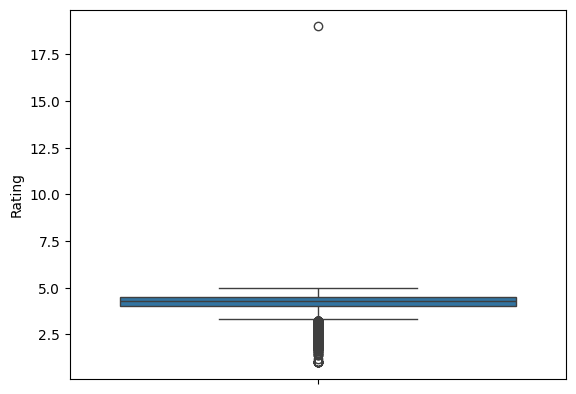

In [180]:
sns.boxplot(df['Rating'])

In [181]:
df[df['Rating']>5]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


In [182]:
df.drop(df[df['Rating'] > 5].index, inplace=True)

In [183]:
Q1 = df['Rating'].quantile(0.25)
Q3 = df['Rating'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: 3.25
Upper Bound: 5.25


In [184]:
outliers = df[
    (df['Rating'] < lower_bound) |
    (df['Rating'] > upper_bound)
]

outliers.shape

(503, 13)

In [185]:
# Preserve genuinely observed ratings
df_rating = df[df["Rating"].notna()].copy()

In [186]:
# Preserve original rating information
df["Rating_Original"] = df["Rating"]
df["Rating_Missing"] = df["Rating"].isna()

In [187]:
# Calculate category-wise median
category_medians = df.groupby("Category")["Rating"].median()

# Fill missing ratings using category median
df["Rating"] = df["Rating"].fillna(
    df["Category"].map(category_medians)
)

# Fallback for any remaining missing values
df["Rating"] = df["Rating"].fillna(
    df["Rating_Original"].median()
)

In [188]:
df['Rating'].isnull().sum()

np.int64(0)

<Axes: ylabel='Rating'>

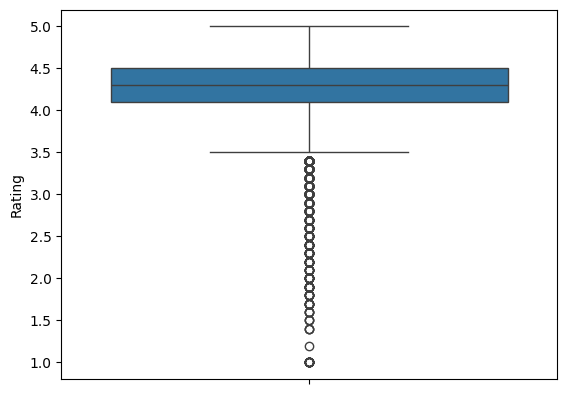

In [189]:
sns.boxplot(df['Rating'])

Key observations
- Most app ratings are concentrated between 4.1 and 4.5, indicating generally positive ratings.
- The distribution is negatively skewed (left-skewed), with a longer tail toward lower ratings.
- Several apps have unusually low ratings, which are displayed as outliers.

In [190]:
df['Rating'].describe()

,Rating
count,10840.000000
mean,4.206661
std,0.481372
min,1.000000
25%,4.100000
50%,4.300000
75%,4.500000
max,5.000000


In [191]:
# Duplicate Analysis

duplicate_rows = df.duplicated().sum()

print("Duplicate Rows:",duplicate_rows)

Duplicate Rows: 483


In [192]:
df.drop_duplicates(inplace=True)

In [193]:
df.shape

(10357, 15)

## Data Type Audit

In [194]:
dtype_df = pd.DataFrame({
    "Column":df.columns,
    "Current Type":df.dtypes.values
})

dtype_df

,Column,Current Type
0,App,object
1,Category,object
2,Rating,float64
3,Reviews,object
4,Size,object
5,Installs,object
6,Type,object
7,Price,object
8,Content Rating,object
9,Genres,object


Expected data type of columns differ from current data type.
Data type issues prevent meaningful analysis.

##  Cardinality Analysis

In [195]:
cardinality = pd.DataFrame({
    "Unique Values":df.nunique()
}).sort_values(
    by="Unique Values",
    ascending=False
)

cardinality

,Unique Values
App,9659
Reviews,6001
Current Ver,2831
Last Updated,1377
Size,461
Genres,119
Price,92
Rating_Original,39
Rating,39
Category,33


1. The dataset contains 9,659 unique app names, indicating a diverse range of applications.
2. The dataset contains 119 unique genres, reflecting diverse app functionalities.
3. The dataset contains 33 unique categories, representing different application segments.

In [196]:
# Inspect Categorical Variables

categorical_cols = df.select_dtypes(
    include="object"
).columns

for col in categorical_cols:

    print("\n")
    print("="*60)

    print(col)

    print("="*60)

    print(df[col].value_counts().head(10))



App
App
ROBLOX                 9
8 Ball Pool            7
Zombie Catchers        6
Bubble Shooter         6
Helix Jump             6
Bowmasters             5
Farm Heroes Saga       5
Zombie Tsunami         5
Angry Birds Classic    5
Granny                 5
Name: count, dtype: int64


Category
Category
FAMILY             1943
GAME               1121
TOOLS               843
BUSINESS            427
MEDICAL             408
PRODUCTIVITY        407
PERSONALIZATION     388
LIFESTYLE           373
COMMUNICATION       366
FINANCE             360
Name: count, dtype: int64


Reviews
Reviews
0    593
1    272
2    213
3    170
4    137
5    108
6     94
7     88
8     72
9     64
Name: count, dtype: int64


Size
Size
Varies with device    1526
11M                    188
13M                    186
12M                    186
14M                    182
15M                    174
17M                    155
26M                    145
16M                    143
19M                    135
Name: count,

#  Data Validation

In [197]:
# Price should never be negative.

invalid_price = df[
    df["Price"].str.contains("-")
]

invalid_price

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Rating_Original,Rating_Missing


There is no negative price recorded in dataset.

In [198]:
# Type should only contain Free, Paid

df["Type"].unique()

array(['Free', 'Paid', nan], dtype=object)

In [199]:
df['Type'].isnull().sum()

np.int64(1)

In [200]:
df.dropna(subset=['Type'], inplace=True)

One missing value was identified in the Type column. Since it represented a negligible proportion of the dataset and could not be reliably inferred, the corresponding row was removed.

## Data Quality Report:



In [201]:
df.isnull().sum()

,0
App,0
Category,0
Rating,0
Reviews,0
Size,0
Installs,0
Type,0
Price,0
Content Rating,0
Genres,0


In [202]:
quality_report = pd.DataFrame({
    "Quality Dimension": [
        "Completeness",
        "Uniqueness",
        "Validity",
        "Consistency"
    ],
    "Status": [
        "Needs Review",
        "Needs Validation",
        "Needs Cleaning",
        "Needs Cleaning"
    ],
    "Comments": [
        "Missing version information detected.",
        "Duplicate records already handled.",
        "Incorrect data types for multiple columns.",
        "Formatting inconsistencies in numeric fields."
    ]
})

quality_report

,Quality Dimension,Status,Comments
0,Completeness,Needs Review,Missing version information detected.
1,Uniqueness,Needs Validation,Duplicate records already handled.
2,Validity,Needs Cleaning,Incorrect data types for multiple columns.
3,Consistency,Needs Cleaning,Formatting inconsistencies in numeric fields.


# Data Preparation





In [203]:
# Review stored as text, convert to integer

df["Reviews"] = pd.to_numeric(
    df["Reviews"],
    errors="coerce"
)

In [204]:
# Validate

df['Reviews'].dtype

dtype('int64')

In [205]:
# Installs stored as "1,000+", Remove commas and +

df["Installs"] = (
    df["Installs"]
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False)
)

In [206]:
df["Installs"] = pd.to_numeric(
    df["Installs"],
    errors="coerce"
)

In [207]:
# Validate

df['Installs'].sample(3)

,Installs
6283,5000
5641,100000
4658,500000


In [208]:
# Price contains $, remove $ and convert data type

df["Price"] = (
    df["Price"]
    .str.replace("$","",regex=False)
)

df["Price"] = pd.to_numeric(
    df["Price"],
    errors="coerce"
)

In [209]:
# Replace invalid values
df["Size"] = df["Size"].replace(
    "Varies with device", np.nan
)

# Convert size into MB
def convert_size(size):

    if pd.isna(size):
        return np.nan

    size = str(size).strip()

    if size.endswith("M"):
        return float(size[:-1])

    elif size.endswith("k"):
        return float(size[:-1]) / 1024

    else:
        return np.nan


df["Size_MB"] = df["Size"].apply(convert_size)

In [210]:
df["Size_MB"] = pd.to_numeric(
    df["Size_MB"],
    errors="coerce"
)

In [211]:
df.drop(columns='Size',inplace=True)

In [212]:
# Change 'Last Updated' Column data type from object to datetime

df["Last Updated"] = pd.to_datetime(
    df["Last Updated"]
)

In [213]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10356 entries, 0 to 10840
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   App              10356 non-null  object        
 1   Category         10356 non-null  object        
 2   Rating           10356 non-null  float64       
 3   Reviews          10356 non-null  int64         
 4   Installs         10356 non-null  int64         
 5   Type             10356 non-null  object        
 6   Price            10356 non-null  float64       
 7   Content Rating   10356 non-null  object        
 8   Genres           10356 non-null  object        
 9   Last Updated     10356 non-null  datetime64[ns]
 10  Current Ver      10348 non-null  object        
 11  Android Ver      10354 non-null  object        
 12  Rating_Original  8892 non-null   float64       
 13  Rating_Missing   10356 non-null  bool          
 14  Size_MB          8831 non-null   float64   

In [214]:
df[df['Content Rating'] == 'Unrated']

,App,Category,Rating,Reviews,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Rating_Original,Rating_Missing,Size_MB
7312,Best CG Photography,FAMILY,4.3,1,500,Free,0.0,Unrated,Entertainment,2015-06-24,5.2,3.0 and up,NaN,True,2.5
8266,DC Universe Online Map,TOOLS,4.1,1186,50000,Free,0.0,Unrated,Tools,2012-02-27,1.3,2.3.3 and up,4.1,False,6.4


# EDA

**1. Marketplace Overview**

What does the Google Play ecosystem look like?

In [215]:
total_apps = len(df)

total_categories = df["Category"].nunique()

avg_rating = round(df["Rating"].mean(),2)

total_installs = df["Installs"].sum()

free_apps = (df["Type"]=="Free").sum()

paid_apps = (df["Type"]=="Paid").sum()

print(f"Total Apps          : {total_apps:,}")
print(f"Categories          : {total_categories}")
print(f"Average Rating      : {avg_rating}")
print(f"Total Installs      : {total_installs:,}")
print(f"Free Apps           : {free_apps:,}")
print(f"Paid Apps           : {paid_apps:,}")

Total Apps          : 10,356
Categories          : 33
Average Rating      : 4.2
Total Installs      : 146,631,914,527
Free Apps           : 9,591
Paid Apps           : 765


**2.  User Satisfaction Analysis**


Are users generally satisfied with apps?

In [216]:
# Descriptive Statistics on 'Rating' Column:

df["Rating"].describe()

,Rating
count,10356.000000
mean,4.203959
std,0.486684
min,1.000000
25%,4.100000
50%,4.300000
75%,4.500000
max,5.000000


In [217]:
df["Rating"].skew()

np.float64(-2.030077300072649)

Text(0, 0.5, 'Frequency')

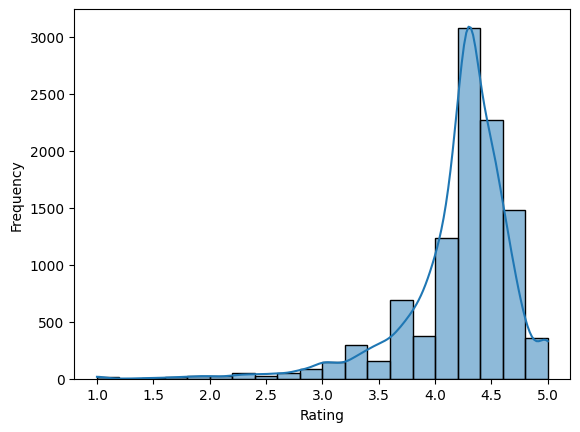

In [218]:
sns.histplot(df["Rating"], bins=20, kde=True)
plt.xlabel("Rating")
plt.ylabel("Frequency")

Indicates presence of More highly-rated apps.

In [219]:
df["Rating"].kurt()

np.float64(7.061002428075013)

Rating column distribution is leptokurtic, indicating it has heavy tails and more extreme outliers than a normal distribution.

**3. Category Competition**

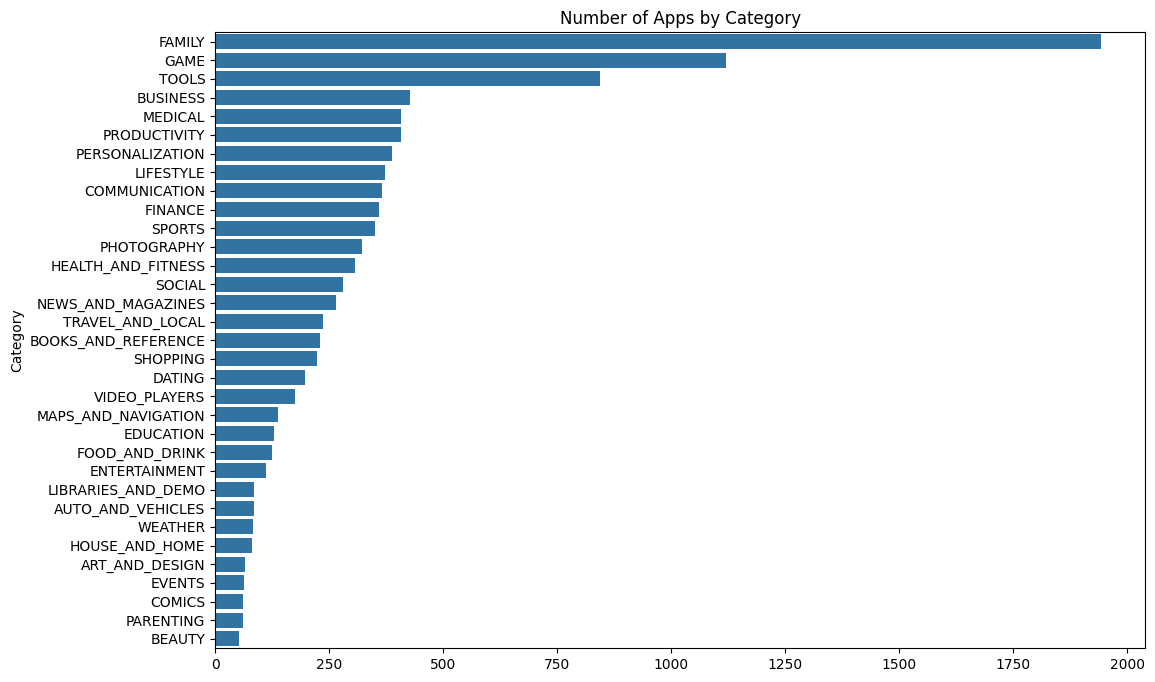

In [220]:
category_count = (
    df["Category"]
    .value_counts()
)

plt.figure(figsize=(12,8))

sns.barplot(
    x=category_count.values,
    y=category_count.index
)

plt.title("Number of Apps by Category")

plt.show()

The ```Family``` category appears highly saturated. Google may consider encouraging developers toward less competitive categories to improve marketplace diversity.

**4. Market Share**


Which categories dominate the marketplace?

In [221]:
category_share = (
    df["Category"]
      .value_counts(normalize=True)
      *100
)

category_share.head()

,proportion
Category,
FAMILY,18.752414
GAME,10.824643
TOOLS,8.140209
BUSINESS,4.123214
MEDICAL,3.939745


**5. User Demand**

Which app categories have the highest total recorded installs?

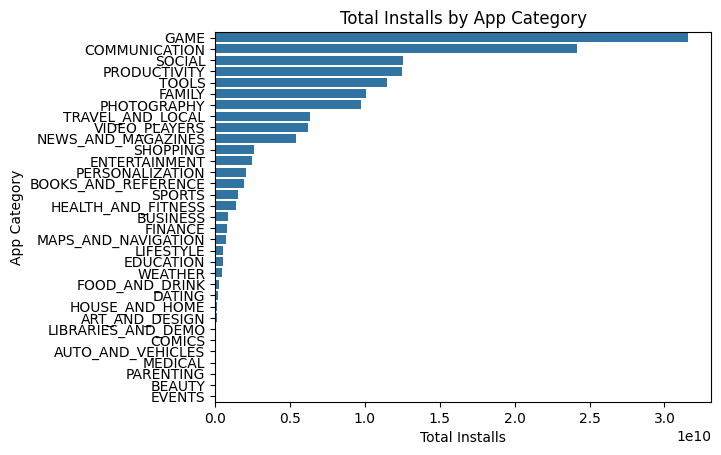

In [222]:
install_summary = (
    df.groupby("Category")["Installs"]
      .sum()
      .sort_values(ascending=False)
)

sns.barplot(x=install_summary.values,
            y=install_summary.index)
plt.title("Total Installs by App Category")
plt.xlabel("Total Installs")
plt.ylabel("App Category")
plt.show()

In [223]:
install_summary = (
    df.groupby("Category")["Installs"]
    .agg(["sum", "mean", "median", "count"])
    .sort_values("sum", ascending=False)
)

install_summary.head()

,sum,mean,median,count
Category,,,,
GAME,31544024415,2.813918e+07,1000000.0,1121
COMMUNICATION,24152276251,6.598983e+07,1000000.0,366
SOCIAL,12513867902,4.469239e+07,1000000.0,280
PRODUCTIVITY,12463091369,3.062185e+07,100000.0,407
TOOLS,11452771915,1.358573e+07,50000.0,843


1. GAME leads in overall demand
GAME has the highest total recorded installs at approximately 31.54 billion, indicating substantial overall demand for gaming apps.
2. COMMUNICATION has high demand with fewer apps
COMMUNICATION has approximately 24.15 billion installs across 366 apps. Its average installs per app are higher than those of GAME.
3. PHOTOGRAPHY has strong typical app performance
PHOTOGRAPHY has a median of 3 million installs, higher than GAME and COMMUNICATION, suggesting that a typical photography app in this dataset has relatively strong installation numbers.


**6. Average Rating by Category**

Which categories make users happiest?

,count,mean,median
Category,,,
EVENTS,45,4.435556,4.50
EDUCATION,129,4.375969,4.40
ART_AND_DESIGN,62,4.358065,4.40
BOOKS_AND_REFERENCE,177,4.347458,4.50
PERSONALIZATION,310,4.333871,4.40
PARENTING,50,4.300000,4.40
GAME,1074,4.281285,4.30
BEAUTY,42,4.278571,4.30
HEALTH_AND_FITNESS,262,4.261450,4.50


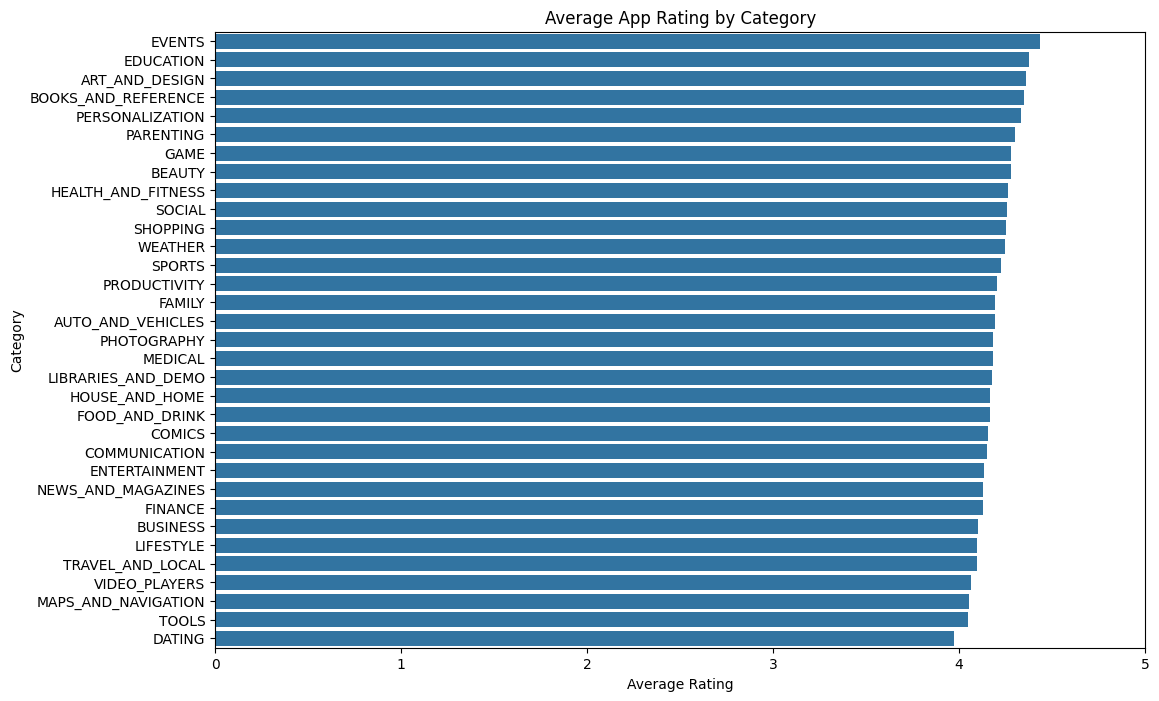

In [224]:
rating_summary = (
    df.groupby("Category")["Rating_Original"].agg(
    ["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

display(rating_summary)

rating_summary = rating_summary.sort_values(
    "mean", ascending=False
)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=rating_summary["mean"],
    y=rating_summary.index
)

plt.title("Average App Rating by Category")
plt.xlabel("Average Rating")
plt.ylabel("Category")
plt.xlim(0, 5)
plt.show()

Categories such as Events and Education consistently achieve higher average user satisfaction, suggesting stronger alignment with user expectations and potentially higher-quality applications.

**7. Free vs Paid**

Does charging money reduce adoption?

In [225]:
df["Type"].value_counts(normalize=True)*100

,proportion
Type,
Free,92.612978
Paid,7.387022


In [226]:
# Usual installations

df.groupby("Type")["Installs"].agg(
    ["mean", "median", "count"]
)

,mean,median,count
Type,,,
Free,1.528127e+07,100000.0,9591
Paid,9.049135e+04,1000.0,765


In [227]:
df.groupby("Type")["Rating"].agg(
    ["mean", "median", "count"]
)

,mean,median,count
Type,,,
Free,4.198248,4.3,9591
Paid,4.275556,4.4,765


Google Apps user likely give higher ratings to paid Apps than free apps even if the installs of free apps is comparatively higher than that of paid apps.

**8. Which content rating group attracts the highest number of installs?**

In [228]:
content_summary = (
    df.groupby('Content Rating')['Installs']
    .agg(['sum', 'mean', 'median', 'count'])
    .sort_values('sum', ascending=False)
)

display(content_summary)

,sum,mean,median,count
Content Rating,,,,
Everyone,100229614961,1.195772e+07,100000.0,8382
Teen,30918280393,2.697930e+07,1000000.0,1146
Everyone 10+,11191271795,2.976402e+07,1000000.0,376
Mature 17+,4290696878,9.598874e+06,500000.0,447
Adults only 18+,2000000,6.666667e+05,500000.0,3
Unrated,50500,2.525000e+04,25250.0,2


Everyone-rated apps generate the highest total installation volume, accounting for approximately 100.23 billion recorded installs. However, Teen and Everyone 10+ apps demonstrate higher median installation counts of 1 million, compared with 100,000 for Everyone apps. This suggests that general-audience apps dominate overall market reach due to their large number, while Teen and Everyone 10+ apps show stronger typical adoption per app. Rare content rating groups should be interpreted cautiously because of their limited sample sizes.

**9. Size Analysis**

Does application size influence user adoption?

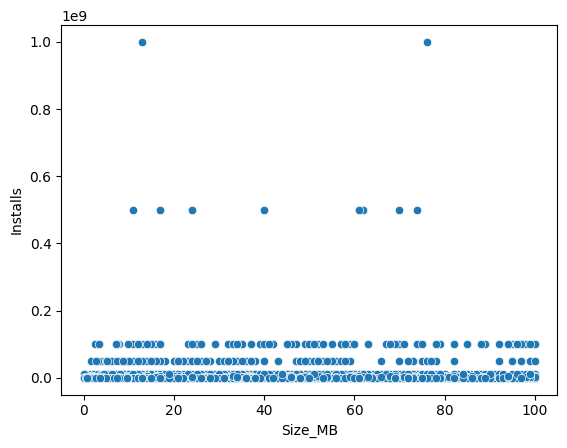

In [229]:
sns.scatterplot(x=df["Size_MB"], y=df["Installs"])
plt.show()

There is no obvious linear relationship between app size and installs.
Since, Install values are extremely skewed, we will visualize size with log of Installs.

<Axes: xlabel='Size_MB', ylabel='Log_Installs'>

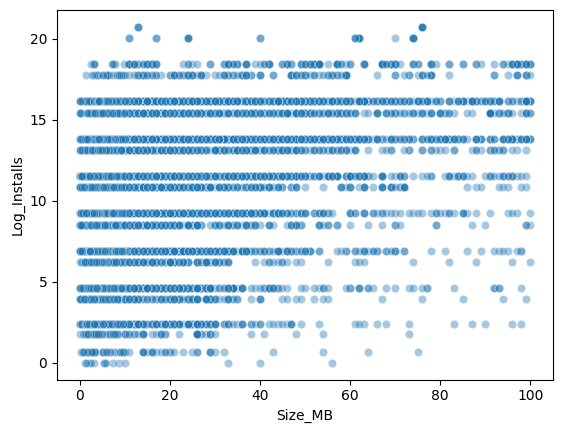

In [230]:
import numpy as np

df["Log_Installs"] = np.log1p(df["Installs"])

sns.scatterplot(
    x="Size_MB",
    y="Log_Installs",
    data=df,
    alpha=0.4
)

Visually it can be said that App size alone does not explain install count as our graph looks like a cloud of points.

But we cannot finally conclude this, as their is no strong evidence. Now, we apply hypothesis and statistical tests.

In [231]:
# Measure the relationship

df[["Size_MB","Log_Installs"]].corr()

,Size_MB,Log_Installs
Size_MB,1.000000,0.334277
Log_Installs,0.334277,1.000000


There is a weak positive linear relationship between application size and install count (after log transformation). Let's confirm that with statistical test:

<Axes: xlabel='Log_Installs', ylabel='Count'>

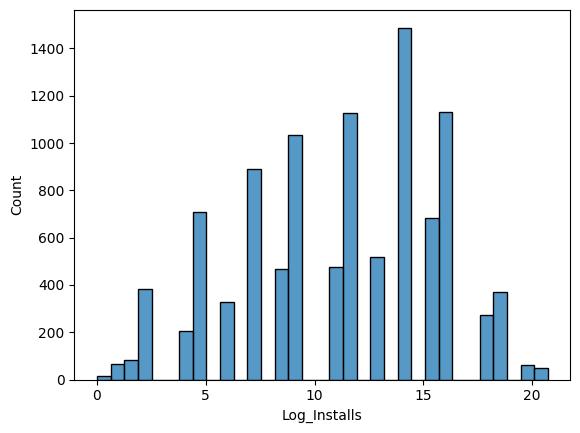

In [232]:
sns.histplot(df['Log_Installs'])

In [233]:
from scipy.stats import spearmanr

corr, p = spearmanr(df["Size_MB"], df["Log_Installs"], nan_policy="omit")

print("Spearman Correlation:", corr)
print("P-value:", p)

Spearman Correlation: 0.34197598130123175
P-value: 8.952863067598333e-241


-> Spearman Correlation=0.3419 means even when looking only at rank order, larger applications tend to have slightly higher installs.

Why Spearman?

Because:

- Installs are not normally distributed.
- Relationship may not be linear.
- Spearman is more robust.

-> Hypothesis

**H₀ (Null)** : There is no relationship between app size and installs.

**H₁** : There is a relationship.

Since P-value is approximately equal to zero, and P < 0.05 .
We Reject H₀.
That means, the observed relationship is statistically significant.



*While application size shows a statistically significant positive association with install count (Spearman ρ = 0.342, p < 0.001), the effect size is relatively weak. This suggests that application size contributes only marginally to app popularity. Other factors such as ratings, reviews, category, and brand reputation are likely to have a substantially greater influence on user adoption.*

Games -> Large Size -> High Installs

```Size``` isn't causing installs.

```Category``` may be the hidden factor.

This is called a **confounding variable.**



**10.  Reviews**

Are reviews a proxy for popularity?

In [234]:
df[
    ["Reviews","Installs"]
].corr()

,Reviews,Installs
Reviews,1.000000,0.634996
Installs,0.634996,1.000000


0.643 indicates a strong positive relationship.

This means: Apps with more reviews generally have more installs.

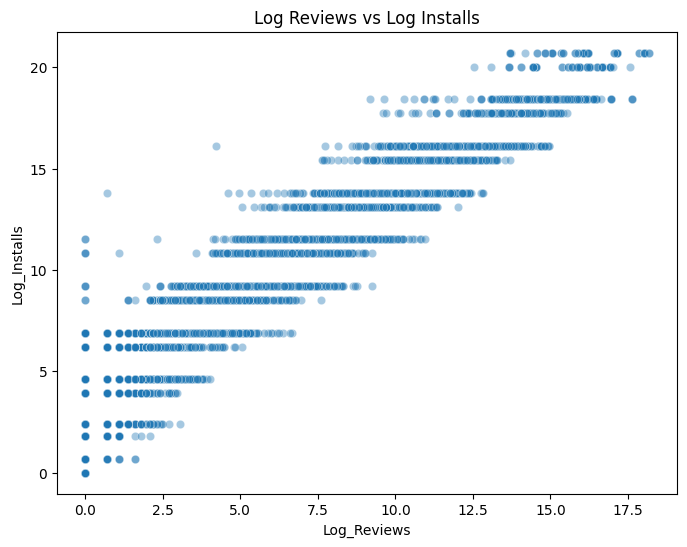

In [235]:
import numpy as np

df["Log_Reviews"] = np.log1p(df["Reviews"])
df["Log_Installs"] = np.log1p(df["Installs"])

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x="Log_Reviews",
    y="Log_Installs",
    alpha=0.4
)

plt.title("Log Reviews vs Log Installs")
plt.show()

Review count is much more informative than application size when estimating app popularity. Correlation is not closer to 1.0, Review count explains part of install behavior—not all of it.

In [236]:
from scipy.stats import spearmanr

corr, p = spearmanr(
    df["Log_Reviews"],
    df["Log_Installs"],
    nan_policy="omit"
)

print(corr)
print(p)

0.9706941256566327
0.0


Spearman is also high (>0.6) and p-value < 0.05, have stronger evidence that the relationship is consistent.

**11. Last Updated**

Do regularly updated apps perform better?
**OR** Do recently updated apps have different average ratings than older apps?

In [237]:
df["Year"] = df["Last Updated"].dt.year

df.groupby("Year")["Rating"].mean()

,Rating
Year,
2010,4.200000
2011,3.966667
2012,3.884615
2013,4.109259
2014,4.064216
2015,4.104846
2016,4.090875
2017,4.136090
2018,4.248493


In [238]:
df.groupby("Year")["Installs"].mean()

,Installs
Year,
2010,1.000000e+05
2011,1.160473e+06
2012,5.381619e+05
2013,9.545034e+05
2014,1.322722e+06
2015,9.194724e+05
2016,1.757244e+06
2017,2.112931e+06
2018,2.027483e+07


In [239]:
reference_date = df["Last Updated"].max()

df["Days_Since_Update"] = (
    reference_date - df["Last Updated"]
).dt.days

In [240]:
bins = [0, 30, 180, 365, 1095, float("inf")]

labels = [
    "Updated in last 30 days",
    "31–180 days ago",
    "181–365 days ago",
    "1–3 years ago",
    "More than 3 years ago"
]

df["Update_Group"] = pd.cut(
    df["Days_Since_Update"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [252]:
update_summary = (
    df.groupby("Update_Group", observed=True)
    .agg(
        Mean_Rating=("Rating_Original", "mean"),
        Median_Rating=("Rating_Original", "median"),
        Mean_Installs=("Installs", "mean"),
        Median_Installs=("Installs", "median"),
        App_Count=("App", "count"),
        Observed_Rating_Count=("Rating_Original", "count")
    )
)

display(update_summary)

,Mean_Rating,Median_Rating,Mean_Installs,Median_Installs,App_Count,Observed_Rating_Count
Update_Group,,,,,,
Updated in last 30 days,4.284840,4.4,3.359386e+07,1000000.0,3399,3120
31–180 days ago,4.197720,4.3,7.922562e+06,100000.0,3157,2675
181–365 days ago,4.120566,4.2,3.108966e+06,10000.0,1354,1060
1–3 years ago,4.067281,4.2,1.438059e+06,10000.0,1851,1519
More than 3 years ago,4.044402,4.1,9.470324e+05,10000.0,595,518


This signifies that the apps updated most frequently after launch are comparatively receive more installs and ratings.

In [242]:
# Use ANOVA

observed_ratings = df[df["Rating_Missing"] == False]

groups = [
    group["Rating"].dropna()
    for _, group in observed_ratings.groupby("Update_Group", observed=False)
]

from scipy.stats import f_oneway

f_stat, p_value = f_oneway(*groups)
print(f_stat)
print(p_value)

63.2428468667137
8.484617118031661e-53


- Null Hypothesis: The average ratings are the same across all update groups.
- Alternative Hypothesis (H₁): At least one update group has a different average rating.

- F = 63.24 is a very large F-value.

It suggests: Between group variation is greater than within group variation.

- P-value is much smaller than 0.05, thus we reject null hypothesis.

Statistical analysis indicates that average application ratings differ significantly across update recency groups (F = 63.24, p < 0.05). This provides strong evidence that the recency of app updates is associated with differences in user satisfaction.

In [243]:
# Use ANOVA

groups = [
    group["Log_Installs"].dropna()
    for _, group in df.groupby("Update_Group", observed=False)
]

from scipy.stats import f_oneway

f_stat, p_value = f_oneway(*groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 331.22531288395504
P-value: 1.1194077634284084e-268


- F = 331.22 is a very large F-value.

It suggests: Between group variation is greater than within group variation.

- P-value is much smaller than 0.05, thus we reject null hypothesis.

Statistical analysis indicates that average application ratings differ significantly across update recency groups (F = 331.22, p < 0.05). This provides strong evidence that the recency of app updates is associated with differences in user satisfaction.

ANOVA provides evidence that average ratings differ significantly across update recency groups.

However, ANOVA alone does not tell you:
- Which specific update groups differ significantly.
- Whether recently updated apps have higher ratings than every other group.
- Whether updating an app causes its rating to increase.

For that, you need to examine group means and perform a post-hoc test such as Tukey's HSD.

In [254]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

observed_ratings = df[df["Rating_Original"].notna()]

tukey_rating = pairwise_tukeyhsd(
    endog=observed_ratings["Rating_Original"],
    groups=observed_ratings["Update_Group"],
    alpha=0.05
)

print(tukey_rating)

                Multiple Comparison of Means - Tukey HSD, FWER=0.05                 
        group1                 group2         meandiff p-adj   lower   upper  reject
------------------------------------------------------------------------------------
     181–365 days ago           1–3 years ago  -0.0533 0.0733 -0.1095   0.003  False
     181–365 days ago         31–180 days ago   0.0772 0.0004  0.0261  0.1282   True
     181–365 days ago   More than 3 years ago  -0.0762 0.0461 -0.1515 -0.0008   True
     181–365 days ago Updated in last 30 days   0.1643    0.0  0.1143  0.2142   True
        1–3 years ago         31–180 days ago   0.1304    0.0  0.0853  0.1756   True
        1–3 years ago   More than 3 years ago  -0.0229 0.9069 -0.0944  0.0486  False
        1–3 years ago Updated in last 30 days   0.2176    0.0  0.1736  0.2615   True
      31–180 days ago   More than 3 years ago  -0.1533    0.0 -0.2208 -0.0858   True
      31–180 days ago Updated in last 30 days   0.0871    0.0  0.

- 181–365 days vs. 1–3 years: significant difference.



- 181–365 days vs. more than 3 years: significant difference.



- 1–3 years vs. more than 3 years: no significant difference.



- 1–3 years vs. updated in last 30 days: significant difference.

In [253]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(
    endog=df["Log_Installs"].dropna(),
    groups=df.loc[df["Log_Installs"].notna(), "Update_Group"],
    alpha=0.05
)

print(tukey)

                Multiple Comparison of Means - Tukey HSD, FWER=0.05                 
        group1                 group2         meandiff p-adj   lower   upper  reject
------------------------------------------------------------------------------------
     181–365 days ago           1–3 years ago  -0.3322 0.1865 -0.7475  0.0831  False
     181–365 days ago         31–180 days ago   1.0828    0.0  0.7055  1.4601   True
     181–365 days ago   More than 3 years ago  -0.2019 0.8713 -0.7731  0.3694  False
     181–365 days ago Updated in last 30 days   3.4265    0.0  3.0533  3.7997   True
        1–3 years ago         31–180 days ago    1.415    0.0   1.075  1.7549   True
        1–3 years ago   More than 3 years ago   0.1303 0.9668  -0.417  0.6776  False
        1–3 years ago Updated in last 30 days   3.7587    0.0  3.4232  4.0942   True
      31–180 days ago   More than 3 years ago  -1.2846    0.0 -1.8037 -0.7656   True
      31–180 days ago Updated in last 30 days   2.3437    0.0  2.

1. Tukey's HSD post-hoc analysis revealed statistically significant differences in mean log-installation levels between apps updated within the last 30 days and all other update recency groups.
2. Apps updated within 31–180 days also differed significantly from several older update groups.
3. However, some older update groups did not demonstrate statistically significant differences.
4. These findings suggest that update recency is associated with app adoption, although they do not establish a causal relationship.

Google should reward actively maintained apps in search rankings. Since, the available dataset only contains the most recent update date for each application. Therefore, update frequency cannot be directly measured. The analysis can only evaluate update recency, not maintenance frequency.



# Market Opportunity Analysis

In [245]:
category_analysis = (
    df.groupby("Category")
      .agg(
          Total_Apps=("App", "count"),
          Avg_Rating=("Rating", "mean"),
          Median_Rating=("Rating", "median"),
          Avg_Reviews=("Reviews", "mean"),
          Avg_Installs=("Installs", "mean"),
          Median_Installs=("Installs", "median"),
          Paid_App_Count=("Type", lambda x: (x=="Paid").sum()),
          Free_App_Count=("Type", lambda x: (x=="Free").sum()),
          Avg_Size=("Size_MB", "mean"),
          Avg_Price=("Price", "mean")
      )
      .round(2)
)

category_analysis

,Total_Apps,Avg_Rating,Median_Rating,Avg_Reviews,Avg_Installs,Median_Installs,Paid_App_Count,Free_App_Count,Avg_Size,Avg_Price
Category,,,,,,,,,,
ART_AND_DESIGN,65,4.36,4.4,26376.00,1912893.85,100000.0,3,62,12.37,0.09
AUTO_AND_VEHICLES,85,4.21,4.3,13690.19,625061.31,100000.0,3,82,20.04,0.16
BEAUTY,53,4.28,4.3,7476.23,513151.89,50000.0,0,53,13.80,0.00
BOOKS_AND_REFERENCE,230,4.38,4.5,95100.99,8332476.42,10000.0,28,202,13.19,0.52
BUSINESS,427,4.18,4.3,28941.85,2022634.34,1000.0,12,415,13.91,0.41
COMICS,60,4.16,4.4,56387.93,934769.17,100000.0,0,60,13.48,0.00
COMMUNICATION,366,4.18,4.3,1642823.91,65989825.82,1000000.0,27,339,11.66,0.23
DATING,196,4.00,4.1,28292.84,1053755.65,100000.0,7,189,15.83,0.16
EDUCATION,130,4.38,4.4,178196.15,4107323.08,1000000.0,4,126,20.08,0.14


In [246]:
# Which categories successfully sell paid apps?

paid_analysis = (
    df[df["Type"] == "Paid"]
    .groupby("Category")
    .agg(
        Paid_App_Count=("App", "count"),
        Median_Installs=("Installs", "median"),
        Avg_Installs=("Installs", "mean"),
        Median_Price=("Price", "median"),
        Avg_Rating=("Rating", "mean"),
        Avg_Reviews=("Reviews", "mean")
    )
)

paid_analysis["Paid_App_Share"] = (
    paid_analysis["Paid_App_Count"] /
    df.groupby("Category")["App"].count()
)

paid_analysis = paid_analysis.sort_values(
    "Median_Installs",
    ascending=False
)

display(paid_analysis.head(10))

,Paid_App_Count,Median_Installs,Avg_Installs,Median_Price,Avg_Rating,Avg_Reviews,Paid_App_Share
Category,,,,,,,
ENTERTAINMENT,2,100000.0,100000.000000,3.99,4.600000,5004.500000,0.018018
WEATHER,8,55000.0,101500.000000,3.49,4.362500,17055.125000,0.097561
EDUCATION,4,50500.0,150500.000000,3.99,4.750000,8661.250000,0.030769
FOOD_AND_DRINK,2,30000.0,30000.000000,4.24,4.350000,1698.500000,0.016129
PARENTING,2,25050.0,25050.000000,4.79,3.350000,4183.000000,0.033333
GAME,83,10000.0,254216.445783,2.99,4.374699,19174.734940,0.074041
MAPS_AND_NAVIGATION,5,10000.0,24220.000000,2.99,3.860000,1437.600000,0.036496
VIDEO_PLAYERS,4,10000.0,17750.000000,1.74,4.100000,3341.750000,0.022857
HEALTH_AND_FITNESS,15,10000.0,31607.333333,3.49,4.420000,3052.866667,0.049020


Weather appears particularly interesting for paid-app adoption, while Game has the largest paid-app ecosystem.

# Sensitivity Analysis:

In [247]:
import pandas as pd
import numpy as np

# Category-level demand and competition
category_metrics = (
    df.groupby("Category")
    .agg(
        App_Count=("App", "nunique"),
        Median_Installs=("Installs", "median")
    )
    .reset_index()
)

# Optional: exclude categories with very few apps
MIN_APPS = 10

category_metrics = category_metrics[
    category_metrics["App_Count"] >= MIN_APPS
].copy()

display(category_metrics.head())

,Category,App_Count,Median_Installs
0,ART_AND_DESIGN,64,100000.0
1,AUTO_AND_VEHICLES,85,100000.0
2,BEAUTY,53,50000.0
3,BOOKS_AND_REFERENCE,222,10000.0
4,BUSINESS,420,1000.0


In [248]:
# Normalize demand and competition

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

category_metrics[["Demand_Score", "Competition_Score"]] = scaler.fit_transform(
    category_metrics[["Median_Installs", "App_Count"]]
)

# Higher competition should reduce opportunity
category_metrics["Low_Competition_Score"] = (
    1 - category_metrics["Competition_Score"]
)

In [249]:
# Test different weight combinations

scenarios = {
    "Demand-focused": {
        "demand_weight": 0.70,
        "competition_weight": 0.30
    },
    "Balanced": {
        "demand_weight": 0.50,
        "competition_weight": 0.50
    },
    "Competition-focused": {
        "demand_weight": 0.30,
        "competition_weight": 0.70
    }
}

for scenario, weights in scenarios.items():

    category_metrics[scenario] = (
        weights["demand_weight"] * category_metrics["Demand_Score"]
        +
        weights["competition_weight"] * category_metrics["Low_Competition_Score"]
    )

    category_metrics[f"{scenario}_Rank"] = (
        category_metrics[scenario]
        .rank(ascending=False, method="min")
        .astype(int)
    )

In [250]:
# Compare rankings across scenarios

rank_columns = [
    "Demand-focused_Rank",
    "Balanced_Rank",
    "Competition-focused_Rank"
]

sensitivity_results = category_metrics[
    ["Category", "App_Count", "Median_Installs"] + rank_columns
].copy()


# Calculate average rank for each category
sensitivity_results["Average_Rank"] = (
    sensitivity_results[rank_columns].mean(axis=1)
)

sensitivity_results["Best_Rank"] = (
    sensitivity_results[rank_columns].min(axis=1)
)

sensitivity_results["Worst_Rank"] = (
    sensitivity_results[rank_columns].max(axis=1)
)

sensitivity_results["Rank_Range"] = (
    sensitivity_results["Worst_Rank"] -
    sensitivity_results["Best_Rank"]
)

sensitivity_results = sensitivity_results.sort_values(
    "Average_Rank"
)

sensitivity_results.head()

,Category,App_Count,Median_Installs,Demand-focused_Rank,Balanced_Rank,Competition-focused_Rank,Average_Rank,Best_Rank,Worst_Rank,Rank_Range
9,ENTERTAINMENT,102,5000000.0,1,1,1,1.000000,1,1,0
24,PHOTOGRAPHY,281,3000000.0,2,2,2,2.000000,2,2,0
32,WEATHER,79,1000000.0,3,3,3,3.000000,3,3,0
8,EDUCATION,119,1000000.0,4,4,4,4.000000,4,4,0
31,VIDEO_PLAYERS,164,1000000.0,5,5,6,5.333333,5,6,1


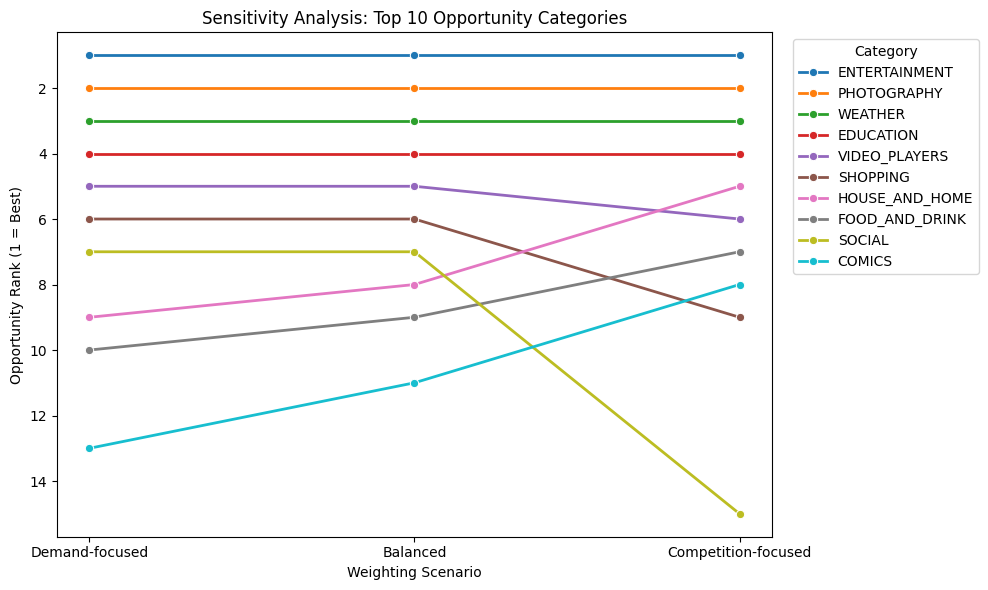

In [251]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select top 10 categories
top10_categories = (
    sensitivity_results
    .sort_values("Average_Rank", ascending=True)
    .head(10)["Category"]
    .tolist()
)

# Filter data for these categories
top10_data = sensitivity_results[
    sensitivity_results["Category"].isin(top10_categories)
].copy()

# Convert to long format for plotting
plot_data = top10_data.melt(
    id_vars="Category",
    value_vars=rank_columns,
    var_name="Scenario",
    value_name="Rank"
)

# Plot
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=plot_data,
    x="Scenario",
    y="Rank",
    hue="Category",
    marker="o",
    linewidth=2
)

plt.gca().invert_yaxis()

plt.title("Sensitivity Analysis: Top 10 Opportunity Categories")
plt.xlabel("Weighting Scenario")
plt.ylabel("Opportunity Rank (1 = Best)")
plt.xticks(
    ticks=[0, 1, 2],
    labels=[
        "Demand-focused",
        "Balanced",
        "Competition-focused"
    ]
)

plt.legend(
    title="Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

- Entertainment, Photography, Weather, and Education consistently rank among the strongest opportunities across demand-focused, balanced, and competition-focused scoring scenarios. Their rankings are relatively stable, suggesting the result is not driven by one particular weighting choice.

- House & Home, Food & Drink, and Comics have relatively low competition, but their overall attractiveness varies with the scoring approach. They may represent more targeted or niche opportunities rather than clear top-priority categories.